# HVAC: 5R1C
This notebook demonstrates how to use a Resistance-Capacitance (RC) thermal model to simulate indoor temperatures and HVAC loads for multiple buildings.
It is modeled after the ISO norm 13790.

## Imports
Import required libraries and set visualization defaults.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from entise.constants import Columns as Cols
from entise.core.generator import Generator as TSGen

%matplotlib inline

## Load Data
We load building parameters from `objects.csv` and simulation data from the `data` folder.

In [2]:
cwd = "."  # Current working directory: change if your kernel is not running in the same folder
objects = pd.read_csv(os.path.join(cwd, "objects.csv"))
data = {}
common_data_folder = "../common_data"
for file in os.listdir(os.path.join(cwd, common_data_folder)):
    if file.endswith(".csv"):
        name = file.split(".")[0]
        data[name] = pd.read_csv(os.path.join(os.path.join(cwd, common_data_folder, file)), parse_dates=True)
data_folder = "data"
for file in os.listdir(os.path.join(cwd, data_folder)):
    if file.endswith(".csv"):
        name = file.split(".")[0]
        data[name] = pd.read_csv(os.path.join(os.path.join(cwd, data_folder, file)), parse_dates=True)

print("Loaded data keys:", list(data.keys()))
print(objects)

Loaded data keys: ['weather', 'windows']
         id  hvac  weather  area[m2]  height[m]  C_m[J K-1]  H_tr_is[W K-1]  \
0   SFH_low  5R1C  weather       140        2.6    11200000             8.4   
1   SFH_mid  5R1C  weather       140        2.6    15400000             5.6   
2  SFH_high  5R1C  weather       140        2.6    19600000             2.8   
3   DFH_low  5R1C  weather       220        2.6    17600000            13.2   
4   DFH_mid  5R1C  weather       220        2.6    24200000             8.8   
5  DFH_high  5R1C  weather       220        2.6    30800000             4.4   
6   MFH_low  5R1C  weather       450        2.8    36000000            27.0   
7   MFH_mid  5R1C  weather       450        2.8    49500000            18.0   
8  MFH_high  5R1C  weather       450        2.8    63000000             9.0   

   H_tr_ms[W K-1]  H_tr_w[W K-1]  H_tr_em[W K-1]  ...  max_temperature[C]  \
0            25.2           50.4              84  ...                  25   
1            1

## Instantiate and Configure Model
Initialize the time series generator and configure it with building objects.

In [3]:
gen = TSGen()
gen.add_objects(objects)

## Run the Simulation
Generate sequential HVAC load and indoor temperature time series for each building.

In [4]:
summary, df = gen.generate(data, workers=1)

  0%|          | 0/9 [00:00<?, ?obj/s]

/tmp/claude-1000/-home-dom38195-code-entise/8892ce24-0669-4994-93de-3087f81790c9/scratchpad/docsenv/lib/python3.12/site-packages/pvlib/solarposition.py:258: UserWarning: Reloading spa to use numba
  warnings.warn('Reloading spa to use numba')


 11%|█         | 1/9 [00:07<01:01,  7.64s/obj]

 22%|██▏       | 2/9 [00:07<00:22,  3.27s/obj]

 33%|███▎      | 3/9 [00:08<00:11,  1.87s/obj]

 44%|████▍     | 4/9 [00:08<00:06,  1.21s/obj]

... (2 outputs left out)

 78%|███████▊  | 7/9 [00:08<00:00,  2.04obj/s]

 89%|████████▉ | 8/9 [00:09<00:00,  2.53obj/s]

100%|██████████| 9/9 [00:09<00:00,  2.97obj/s]

100%|██████████| 9/9 [00:09<00:00,  1.03s/obj]

## Results Summary
Below is a summary of the annual heating and cooling demands (in kWh/a) and peak loads (kW).

In [5]:
print("Summary:")
summary_kwh = (summary / 1000).round(0).astype(int)
summary_kwh = summary_kwh.rename(columns=lambda x: x.replace("[W]", "[kW]").replace("[Wh]", "[kWh]"))
print(summary_kwh.to_string())

Summary:
          heating:demand[kWh]  heating:load_max[kW]  cooling:demand[kWh]  cooling:load_max[kW]
SFH_low                  7274                     3                 4260                     5
SFH_mid                  6875                     3                 4136                     5
SFH_high                 6478                     3                 4013                     4
DFH_low                 10986                     5                 6881                     8
DFH_mid                 10362                     5                 6688                     7
DFH_high                 9744                     5                 6499                     7
MFH_low                 24526                    11                13628                    16
MFH_mid                 23242                    11                13222                    15
MFH_high                21967                    11                12825                    14


## Visualization of Results
Visualize indoor temperature, heating, and cooling loads for a selected building.

In [6]:
# Select building ID to visualize
building_id = summary.index[0]  # Change index to visualize different buildings
building_data = df[building_id]["hvac"]

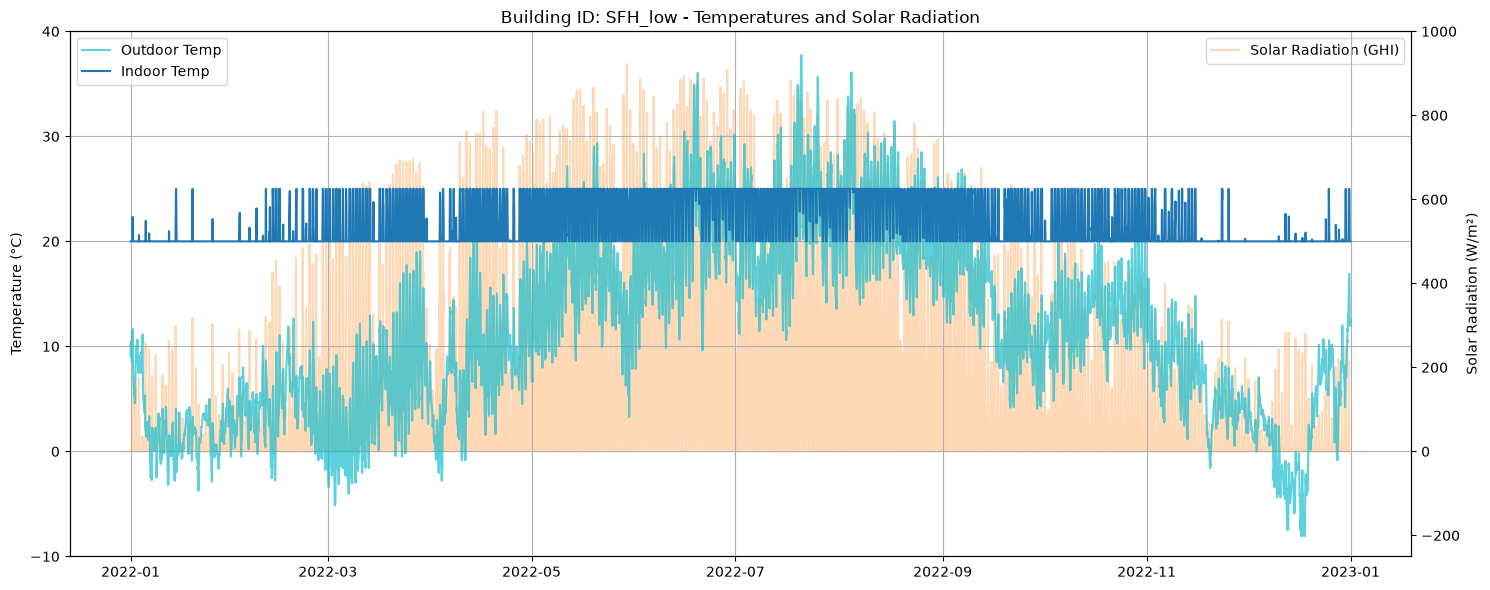

In [7]:
# Figure 1: Indoor & Outdoor Temperature and Solar Radiation (GHI)
fig, ax1 = plt.subplots(figsize=(15, 6))

# Solar radiation plot (GHI) with separate y-axis
ax2 = ax1.twinx()
ax2.plot(
    building_data.index, data["weather"][Cols.SOLAR_GHI], label="Solar Radiation (GHI)", color="tab:orange", alpha=0.3
)
ax2.set_ylabel("Solar Radiation (W/m²)")
ax2.legend(loc="upper right")
ax2.set_ylim(-250, 1000)

# Temperature plot
ax1.plot(building_data.index, data["weather"][f"{Cols.TEMP_AIR}@2m"], label="Outdoor Temp", color="tab:cyan", alpha=0.7)
ax1.plot(building_data.index, building_data[Cols.TEMP_IN], label="Indoor Temp", color="tab:blue")
ax1.set_ylabel("Temperature (°C)")
ax1.set_title(f"Building ID: {building_id} - Temperatures and Solar Radiation")
ax1.legend(loc="upper left")
ax1.grid(True)
ax1.set_ylim(-10, 40)

ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)  # required to see through ax1 to ax2
plt.tight_layout()
plt.show()

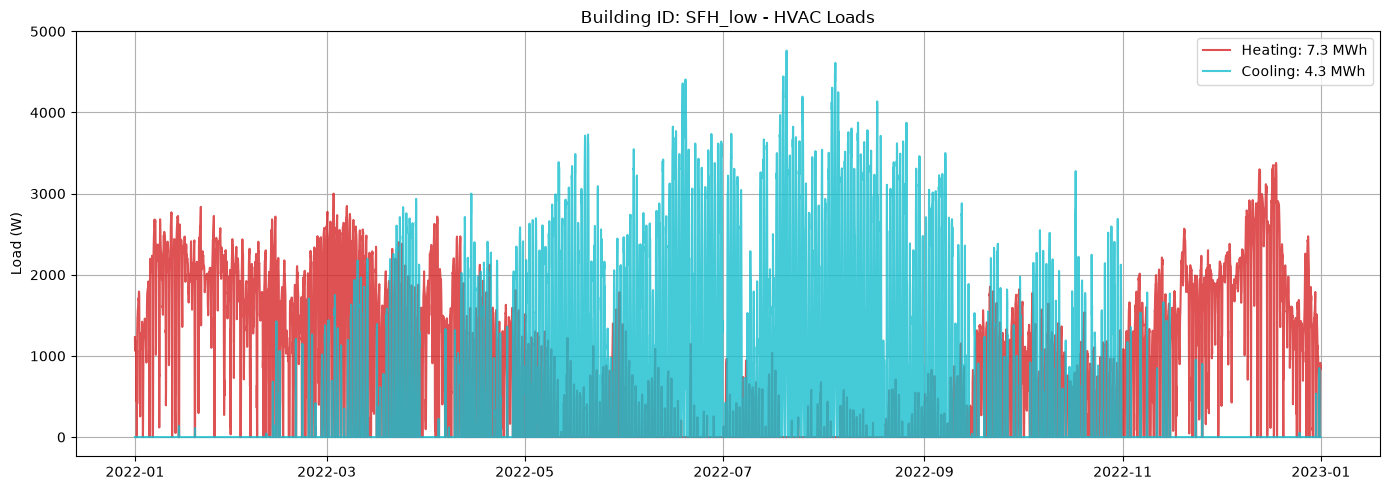

In [8]:
# Figure 2: Heating and Cooling Loads
fig, ax = plt.subplots(figsize=(14, 5))
heating_MWh = summary.loc[building_id, "heating:demand[Wh]"] / 1e6
cooling_MWh = summary.loc[building_id, "cooling:demand[Wh]"] / 1e6
(line1,) = ax.plot(
    building_data.index,
    building_data["heating:load[W]"],
    label=f"Heating: {heating_MWh:.1f} MWh",
    color="tab:red",
    alpha=0.8,
)
(line2,) = ax.plot(
    building_data.index,
    building_data["cooling:load[W]"],
    label=f"Cooling: {cooling_MWh:.1f} MWh",
    color="tab:cyan",
    alpha=0.8,
)
# Create the combined legend in the upper left corner
ax.set_ylabel("Load (W)")
ax.set_title(f"Building ID: {building_id} - HVAC Loads")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

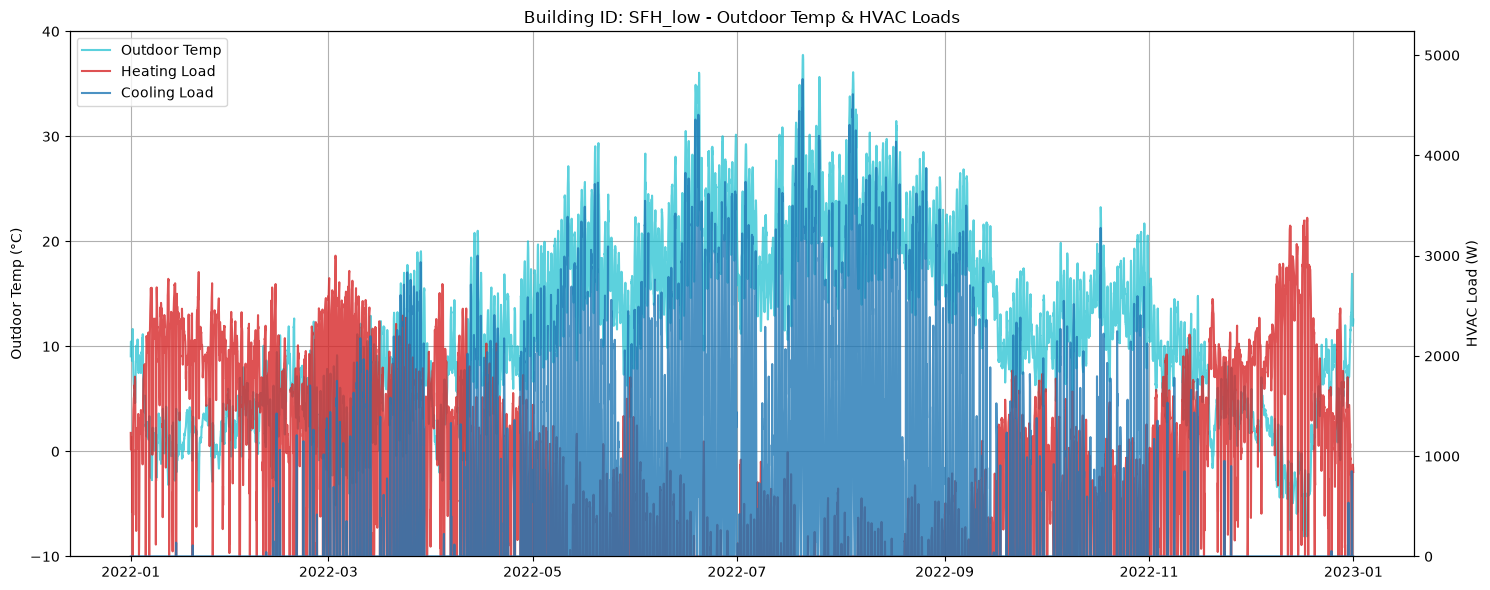

In [9]:
# Figure 3: Outdoor Temperature with Heating & Cooling Loads
fig, ax1 = plt.subplots(figsize=(15, 6))

# Plot outdoor temperature on left y-axis
air_temp = data["weather"][f"{Cols.TEMP_AIR}@2m"]
ax1.plot(building_data.index, air_temp, label="Outdoor Temp", color="tab:cyan", alpha=0.7)

ax1.set_ylabel("Outdoor Temp (°C)")
ax1.set_ylim(air_temp.min().round() - 2, air_temp.max().round() + 2)

# Create second y-axis for loads
ax2 = ax1.twinx()
ax2.plot(building_data.index, building_data["heating:load[W]"], label="Heating Load", color="tab:red", alpha=0.8)
ax2.plot(building_data.index, building_data["cooling:load[W]"], label="Cooling Load", color="tab:blue", alpha=0.8)
ax2.set_ylabel("HVAC Load (W)")
ax2.set_ylim(
    min(building_data["heating:load[W]"].min(), building_data["cooling:load[W]"].min()) * 1.1,
    max(building_data["heating:load[W]"].max(), building_data["cooling:load[W]"].max()) * 1.1,
)

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

ax1.set_title(f"Building ID: {building_id} - Outdoor Temp & HVAC Loads")
ax1.grid(True)
fig.tight_layout()
plt.show()

## Next Steps
You can further explore:
- Adjusting building parameters in `objects.csv`
- Incorporating or excluding additional data (e.g., internal gains, solar gains)
- Investigate how different ventilation strategies impact a buildings energy demand (ventilation)
- Automating analysis for larger building datasets